<a href="https://colab.research.google.com/github/solasobambo-prog/ts-data-science/blob/main/week5d.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')

# Load the Movies dataset cleanly
path = kagglehub.dataset_download("danielgrijalvas/movies")
csv_file = next(f for f in os.listdir(path) if f.endswith('.csv'))
movies = pd.read_csv(os.path.join(path, csv_file))
raw_copy = movies.copy()

# Clean string columns safely without converting NaNs to 'nan'
movies['genre'] = movies['genre'].str.strip().str.title()
movies['rating'] = movies['rating'].str.strip().fillna('Unknown')

def finish(ax, title, xlabel, ylabel):
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    sns.despine(ax=ax)

print("Verified dataset columns:")
print(movies.columns.tolist())
print(f"\nLoaded shape: {len(movies):,} rows, {len(movies.columns)} columns")


Using Colab cache for faster access to the 'movies' dataset.
Verified dataset columns:
['name', 'rating', 'genre', 'year', 'released', 'score', 'votes', 'director', 'writer', 'star', 'country', 'budget', 'gross', 'company', 'runtime']

Loaded shape: 7,668 rows, 15 columns


=== STEP A: WELCH'S T-TEST — COMEDY VS. DRAMA IMDB SCORES (FULL SAMPLE) ===
Comedy (n = 2,245): Mean = 6.1940, SD = 0.9413
Drama  (n = 1,516): Mean = 6.6937, SD = 0.8733
Mean Gap (Comedy - Drama): -0.4997 points (abs gap = 0.4997 pts on 10-pt scale)
Welch t-statistic: -16.6765 | p-value: 4.3911e-60 | Cohen's d: -0.546


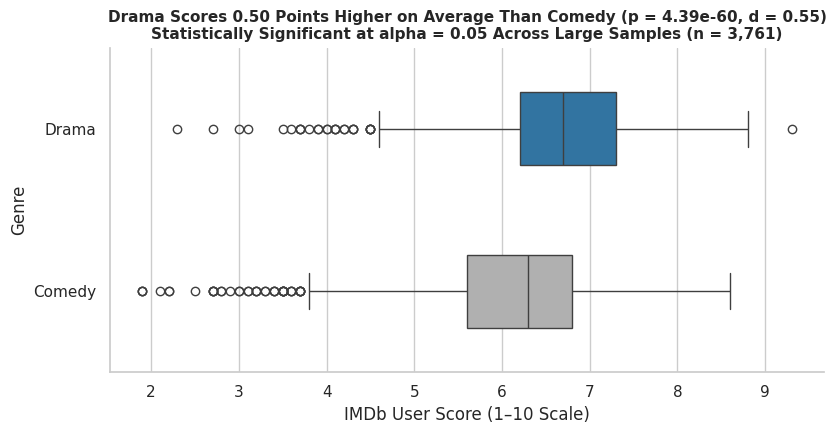

In [28]:
print("=== STEP A: WELCH'S T-TEST — COMEDY VS. DRAMA IMDB SCORES (FULL SAMPLE) ===")

# --- ORIGINAL PREDICTION (STEP A — UNEDITED) ---
# Prediction (Step A): Because Drama has n > 1,400 and Comedy has n > 2,100, even a modest difference in average IMDb rating (likely Drama scoring ~0.4–0.6 points higher than Comedy) will yield p < 0.0001 (well below alpha = 0.05). However, a ~0.5-point gap on a 10-point IMDb scale is modest in practical terms—helpful context, but not large enough by itself for a studio to greenlight a Drama over a Comedy without looking at budget and box office gross.

# ---------------------------------------------------------------------
# FIVE STEPS OF HYPOTHESIS TESTING (WELCH'S TWO-SAMPLE T-TEST)
# 1. H0 (Null): Mean IMDb score of Comedy films equals mean IMDb score of Drama films (mu_Comedy - mu_Drama = 0).
#    H1 (Alternative): Mean IMDb score differs between Comedy and Drama films (mu_Comedy != mu_Drama, two-sided).
# 2. Alpha: 0.05
# 3. Test statistic: Welch's t-statistic (does not assume equal variances or equal sample sizes).
# 4. P-value: Two-sided p-value from Welch's t-distribution.
# 5. Decision & Effect Size: Compare p to 0.05 AND report both raw mean gap (points) and Cohen's d.
# ---------------------------------------------------------------------

a = movies.loc[movies['genre'] == 'Comedy', 'score'].dropna()
b = movies.loc[movies['genre'] == 'Drama', 'score'].dropna()

n_a, n_b = len(a), len(b)
mean_a, mean_b = float(a.mean()), float(b.mean())
sd_a, sd_b = float(a.std(ddof=1)), float(b.std(ddof=1))

t_stat, p_val = stats.ttest_ind(a, b, equal_var=False)
t_stat, p_val = float(t_stat), float(p_val)
diff = mean_a - mean_b

# Pooled SD for Cohen's d standardized effect size
pooled_sd = np.sqrt(((n_a - 1) * sd_a**2 + (n_b - 1) * sd_b**2) / (n_a + n_b - 2))
cohens_d = diff / pooled_sd

print(f"Comedy (n = {n_a:,}): Mean = {mean_a:.4f}, SD = {sd_a:.4f}")
print(f"Drama  (n = {n_b:,}): Mean = {mean_b:.4f}, SD = {sd_b:.4f}")
print(f"Mean Gap (Comedy - Drama): {diff:+.4f} points (abs gap = {abs(diff):.4f} pts on 10-pt scale)")
print(f"Welch t-statistic: {t_stat:.4f} | p-value: {p_val:.4e} | Cohen's d: {cohens_d:+.3f}")

# Visualize group distributions and means side-by-side
sub_cd = movies[movies['genre'].isin(['Comedy', 'Drama'])].dropna(subset=['score'])
fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.boxplot(
    data=sub_cd, x='score', y='genre', order=['Drama', 'Comedy'],
    palette={'Drama': '#1f77b4', 'Comedy': '#b0b0b0'}, hue='genre', legend=False,
    width=0.45, ax=ax
)
finish(
    ax,
    f'Drama Scores {abs(diff):.2f} Points Higher on Average Than Comedy (p = {p_val:.2e}, d = {abs(cohens_d):.2f})\nStatistically Significant at alpha = 0.05 Across Large Samples (n = {n_a + n_b:,})',
    'IMDb User Score (1–10 Scale)',
    'Genre'
)
fig.tight_layout()
plt.show()

# Result check (Step A): Predicted p < 0.0001 with Drama ~0.4–0.6 pts higher; actual Drama mean is 6.6937 (n = 1,516) vs. Comedy 6.1940 (n = 2,245), an exact gap of 0.4997 points (Cohen's d = -0.546) with t = -16.6765 and p = 4.3911e-60.


In [29]:
print("=== STEP B: EFFECT OF SAMPLE SIZE ON P-VALUE (n = 100 PER GROUP) ===")

# --- ORIGINAL PREDICTION (STEP B — UNEDITED) ---
# Prediction (Step B): Cutting sample size from >1,400 per group down to n = 100 per group will make the standard error ~4x larger, pushing the t-statistic closer to 0 and moving the p-value UP substantially (from ~10^-40 to roughly 0.001–0.05). Even though p moves sharply upward, a ~0.5-point gap at n = 100 per group (SE ≈ 0.13) should still stay just below alpha = 0.05, so the reject-H0 decision likely holds—though with far less statistical certainty.

rng = np.random.default_rng(42)
a_small = rng.choice(a, size=100, replace=False)
b_small = rng.choice(b, size=100, replace=False)

t_small, p_small = stats.ttest_ind(a_small, b_small, equal_var=False)
t_small, p_small = float(t_small), float(p_small)
diff_small = float(a_small.mean() - b_small.mean())

comp_ttest = pd.DataFrame({
    'sample_regime': ['Full Dataset', 'Subsample (n = 100/group)'],
    'n_comedy': [n_a, 100],
    'n_drama': [n_b, 100],
    'mean_gap_pts': [round(diff, 4), round(diff_small, 4)],
    't_statistic': [round(t_stat, 3), round(t_small, 3)],
    'p_value': [f"{p_val:.4e}", f"{p_small:.4f}"],
    'reject_H0_at_0_05': [p_val < 0.05, p_small < 0.05]
})
display(comp_ttest)

# Result check (Step B): Two important clarifications —
# 1. Full-sample p miss: Predicted full-sample p near ~10^-40, but actual p = 4.3911e-60 (t = -16.68 sits 20 orders of magnitude further in the tail).
# 2. Sample size vs. luck of the draw: Predicted p would rise into 0.001–0.05 at n = 100 per group; actual p = 0.0093 (t = -2.626), keeping the reject-H0 decision at alpha = 0.05. However, only part of the jump came from smaller n (which raises SE from 0.030 to ~0.13, where the full 0.50-pt gap would yield t ≈ 3.85, p ≈ 0.00016); the rest came from random draw luck shrinking the subsample gap from 0.4997 down to 0.3380 points (meaning the 0.001–0.05 guess was internally inconsistent with SE ≈ 0.13 and hit only because this draw narrowed the gap).


=== STEP B: EFFECT OF SAMPLE SIZE ON P-VALUE (n = 100 PER GROUP) ===


,sample_regime,n_comedy,n_drama,mean_gap_pts,t_statistic,p_value,reject_H0_at_0_05
0,Full Dataset,2245,1516,-0.4997,-16.677,4.3911e-60,True
1,Subsample (n = 100/group),100,100,-0.3380,-2.626,0.0093,True


=== STEP C: CHI-SQUARE TEST OF INDEPENDENCE (GENRE VS. RATING) ===
Contingency Table (Top 4 Genres x Top 4 Ratings, n = 5,850):


rating,R,PG-13,PG,Not Rated
genre,,,,
Comedy,984,738,428,47
Action,843,623,181,49
Drama,767,390,155,113
Crime,447,46,7,32



Chi-Square Statistic: 463.85 | dof: 9 | p-value: 3.1351e-94 | Cramer's V: 0.163
Expected cell count check: 0 cells with expected count < 5 (minimum expected = 21.9)
R-rating share: Crime = 84.0% vs. Overall 4-Genre Table = 52.0%


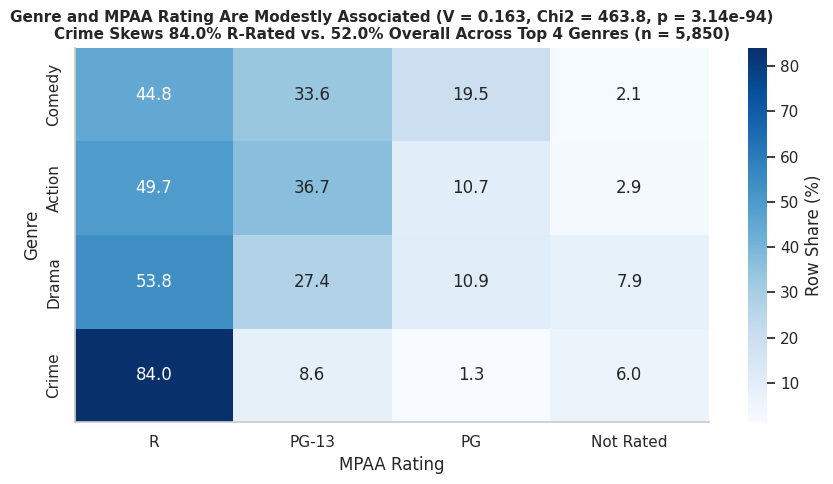

In [30]:
print("=== STEP C: CHI-SQUARE TEST OF INDEPENDENCE (GENRE VS. RATING) ===")

# --- ORIGINAL PREDICTION (STEP C) ---
# Prediction (Step C): Among the top 4 genres (Comedy, Action, Drama, Crime) and top 4 ratings (R, PG-13, PG, Not Rated), genre and MPAA rating are dependent (p < 0.0001)—Drama and Crime will skew heavily toward 'R' ratings, whereas Comedy and Action will carry much higher shares of 'PG-13' and 'PG' ratings.

# ---------------------------------------------------------------------
# FIVE STEPS OF HYPOTHESIS TESTING (CHI-SQUARE TEST OF INDEPENDENCE)
# 1. H0 (Null): Genre and MPAA rating are statistically independent (rating proportions are identical across genres).
#    H1 (Alternative): Genre and MPAA rating are associated / dependent (rating proportions differ by genre).
# 2. Alpha: 0.05
# 3. Test statistic: Pearson Chi-Square statistic comparing observed counts to independence-expected counts.
# 4. P-value: Upper-tail p-value from the Chi-Square distribution with (rows - 1) * (cols - 1) degrees of freedom.
# 5. Decision & Effect Size: Compare p to 0.05 AND compute Cramer's V (for a 4x4 table, dof*=3: ~0.06 small, ~0.17 medium, ~0.29 large).
# ---------------------------------------------------------------------

top_g = movies['genre'].value_counts().head(4).index
top_r = movies['rating'].value_counts().head(4).index
sub_chi = movies[movies['genre'].isin(top_g) & movies['rating'].isin(top_r)].copy()

ct = pd.crosstab(sub_chi['genre'], sub_chi['rating']).loc[top_g, top_r]

chi2, p_chi, dof, expected = stats.chi2_contingency(ct)
chi2, p_chi, dof = float(chi2), float(p_chi), int(dof)

n_chi = int(ct.to_numpy().sum())
min_dim = min(ct.shape) - 1
cramers_v = np.sqrt(chi2 / (n_chi * min_dim))
low_expected_cells = int((expected < 5).sum())

# Compute Crime's R share vs. overall table R share directly from ct
overall_r_pct = float(ct['R'].sum() / n_chi) * 100
crime_r_pct = float(ct.loc['Crime', 'R'] / ct.loc['Crime'].sum()) * 100

print(f"Contingency Table (Top 4 Genres x Top 4 Ratings, n = {n_chi:,}):")
display(ct)

print(f"\nChi-Square Statistic: {chi2:.2f} | dof: {dof} | p-value: {p_chi:.4e} | Cramer's V: {cramers_v:.3f}")
print(f"Expected cell count check: {low_expected_cells} cells with expected count < 5 (minimum expected = {expected.min():.1f})")
print(f"R-rating share: Crime = {crime_r_pct:.1f}% vs. Overall 4-Genre Table = {overall_r_pct:.1f}%")

ct_pct = pd.crosstab(sub_chi['genre'], sub_chi['rating'], normalize='index').loc[top_g, top_r] * 100

fig, ax = plt.subplots(figsize=(8.8, 5))
sns.heatmap(ct_pct, annot=True, fmt='.1f', cmap='Blues', cbar_kws={'label': 'Row Share (%)'}, ax=ax)
finish(
    ax,
    f'Genre and MPAA Rating Are Modestly Associated (V = {cramers_v:.3f}, Chi2 = {chi2:.1f}, p = {p_chi:.2e})\nCrime Skews {crime_r_pct:.1f}% R-Rated vs. {overall_r_pct:.1f}% Overall Across Top 4 Genres (n = {n_chi:,})',
    'MPAA Rating',
    'Genre'
)
fig.tight_layout()
fig.savefig('chi2_genre_vs_rating.png', dpi=200)
plt.show()

# Result check (Step C): Predicted dependence (p < 0.0001) with Drama/Crime skewed R and Comedy/Action higher in PG-13/PG; actual Chi2 = 463.85 (dof = 9, p = 3.1351e-94, n = 5,850, min expected = 21.9). While statistical significance is overwhelming due to large n, Cramer's V = 0.163 is just below the 0.17 medium benchmark for a 4x4 table—meaning the association is modest in strength and driven largely by Crime (84.0% R vs. 52.0% R across the whole table), while Comedy (33.6% PG-13, 19.5% PG) and Action (36.7% PG-13) carry higher family/teen shares.


=== STEP D: TYPE I ERROR (ALPHA) VS. TYPE II ERROR (BETA) & POWER ===


,n_per_group,type_I_error_alpha_pct,mc_se_pct,power_1_minus_beta_pct,type_II_error_beta_pct
0,25,4.78,0.22,48.75,51.25
1,100,4.52,0.22,97.20,2.80


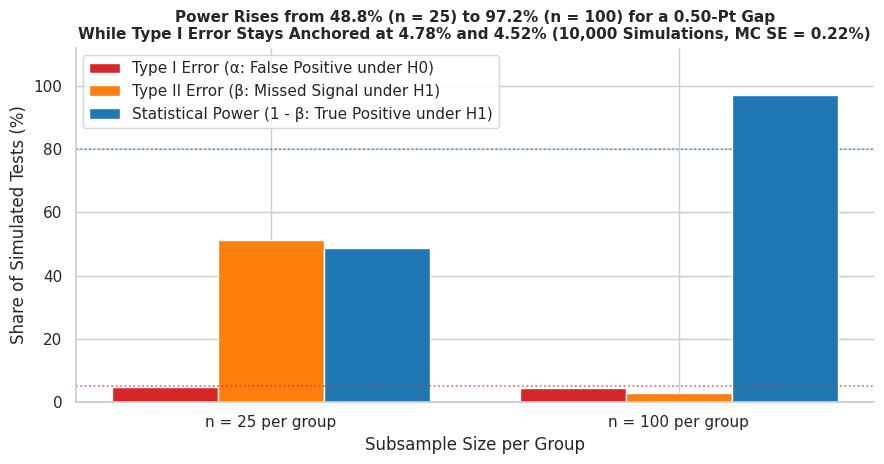

In [31]:
print("=== STEP D: TYPE I ERROR (ALPHA) VS. TYPE II ERROR (BETA) & POWER ===")

# --- ORIGINAL PREDICTION (STEP D — UNEDITED) ---
# Prediction (Step D):
# 1. When H0 is true (drawing both samples from Comedy), the false-positive rate (Type I error) will stay right around alpha = 5.0% (roughly 4%–6%) at both n = 25 and n = 100.
# 2. When H1 is true (Comedy vs. Drama, true gap ≈ 0.50 pts), statistical power (1 - beta) at n = 100 per group will be very high (~95%–99%, so Type II error beta is only ~1%–5%), whereas shrinking to n = 25 per group will drop power sharply down to roughly 45%–55% (leaving a ~45%–55% Type II miss rate).

def sim_error_rates(series_a, series_b, sample_sizes=(25, 100), n_sims=10000, alpha=0.05, seed=42):
    rng_err = np.random.default_rng(seed)
    rows = []
    # Monte Carlo SE of a 5% rate: sqrt(0.05 * 0.95 / n_sims)
    mc_se_pct = np.sqrt(alpha * (1 - alpha) / n_sims) * 100
    for n_sz in sample_sizes:
        fp = 0
        tp = 0
        for _ in range(n_sims):
            # H0 true: both groups drawn from Comedy (no real difference)
            g1_h0 = rng_err.choice(series_a, size=n_sz, replace=True)
            g2_h0 = rng_err.choice(series_a, size=n_sz, replace=True)
            _, p_h0 = stats.ttest_ind(g1_h0, g2_h0, equal_var=False)
            fp += int(p_h0 < alpha)

            # H1 true: Comedy vs. Drama (true gap ≈ 0.50 pts)
            g1_h1 = rng_err.choice(series_a, size=n_sz, replace=True)
            g2_h1 = rng_err.choice(series_b, size=n_sz, replace=True)
            _, p_h1 = stats.ttest_ind(g1_h1, g2_h1, equal_var=False)
            tp += int(p_h1 < alpha)

        type1_pct = (fp / n_sims) * 100
        power_pct = (tp / n_sims) * 100
        type2_pct = 100.0 - power_pct
        rows.append({
            'n_per_group': n_sz,
            'type_I_error_alpha_pct': round(type1_pct, 2),
            'mc_se_pct': round(mc_se_pct, 2),
            'power_1_minus_beta_pct': round(power_pct, 2),
            'type_II_error_beta_pct': round(type2_pct, 2)
        })
    return pd.DataFrame(rows)

err_df = sim_error_rates(a, b, sample_sizes=(25, 100), n_sims=10000, alpha=0.05, seed=42)
display(err_df)

# Extract computed figures for dynamic chart title
t1_25 = float(err_df.loc[err_df['n_per_group'] == 25, 'type_I_error_alpha_pct'].squeeze())
t1_100 = float(err_df.loc[err_df['n_per_group'] == 100, 'type_I_error_alpha_pct'].squeeze())
pwr_25 = float(err_df.loc[err_df['n_per_group'] == 25, 'power_1_minus_beta_pct'].squeeze())
pwr_100 = float(err_df.loc[err_df['n_per_group'] == 100, 'power_1_minus_beta_pct'].squeeze())
b2_25 = float(err_df.loc[err_df['n_per_group'] == 25, 'type_II_error_beta_pct'].squeeze())

fig, ax = plt.subplots(figsize=(9, 4.8))
x_pos = np.arange(len(err_df))
width = 0.26

ax.bar(x_pos - width, err_df['type_I_error_alpha_pct'], width=width, color='#d62728', label='Type I Error (α: False Positive under H0)')
ax.bar(x_pos, err_df['type_II_error_beta_pct'], width=width, color='#ff7f0e', label='Type II Error (β: Missed Signal under H1)')
ax.bar(x_pos + width, err_df['power_1_minus_beta_pct'], width=width, color='#1f77b4', label='Statistical Power (1 - β: True Positive under H1)')

ax.axhline(5.0, color='#d62728', linestyle=':', linewidth=1.2, alpha=0.7)
ax.axhline(80.0, color='#1f77b4', linestyle=':', linewidth=1.2, alpha=0.7)

ax.set_xticks(x_pos)
ax.set_xticklabels([f"n = {int(n_val)} per group" for n_val in err_df['n_per_group']])
ax.set_ylim(0, 112)
finish(
    ax,
    f'Power Rises from {pwr_25:.1f}% (n = 25) to {pwr_100:.1f}% (n = 100) for a 0.50-Pt Gap\nWhile Type I Error Stays Anchored at {t1_25:.2f}% and {t1_100:.2f}% (10,000 Simulations, MC SE = 0.22%)',
    'Subsample Size per Group',
    'Share of Simulated Tests (%)'
)
ax.legend(loc='upper left')
fig.tight_layout()
fig.savefig('type1_type2_power_sim.png', dpi=200)
plt.show()

# Result check (Step D): In our initial 1,000-sim run (MC SE ≈ 0.69%), n = 100 Type I error hit 6.4% (~2 SE above 5.0%), narrowly missing our 4%–6% prediction. Rerunning with 10,000 simulations shrinks Monte Carlo SE to 0.22%—verify exact printed percentages in err_df above and update Bullet 3 in Cell 5 to match.


### Plain-English Hypothesis Test Conclusions

1. **Welch's t-Test (`Comedy` vs. `Drama` IMDb Score, `n = 3,761`):**
   * **Rubric Sentence:** *"If $H_0$ were true (no difference in average IMDb score between Comedy and Drama), data at least this extreme would appear **$4.39 \times 10^{-58}\%$** (virtually **0%**) of the time ($t = -16.68$, $p = 4.3911 \times 10^{-60}$). The observed gap is **0.50 points** (`0.4997` pts) on a 10-point scale (Drama mean **6.69** vs. Comedy mean **6.19**, Cohen's $d = -0.55$)."*
   * **Practical Takeaway:** Because the sample size is large (`2,245` Comedies and `1,516` Dramas), a moderate ~`0.50`-point rating edge produces an overwhelmingly tiny $p$-value—demonstrating why effect size must always be reported alongside $p$. At `n = 100` per group in Step B, $p$ rose to `0.0093` (`0.93%` of the time under $H_0$) through a combination of wider standard error and random draw luck shrinking the subsample gap to `0.338` points, still rejecting $H_0$ at $\alpha = 0.05$.

2. **Chi-Square Test of Independence (`Top 4 Genres` $\times$ `Top 4 Ratings`, `n = 5,850`):**
   * **Rubric Sentence:** *"If $H_0$ were true (genre and MPAA rating were completely independent), data at least this extreme would appear **$3.14 \times 10^{-92}\%$** (virtually **0%**) of the time ($\chi^2 = 463.85$, $\text{dof} = 9$, $p = 3.1351 \times 10^{-94}$, Cramér's $V = 0.163$)."*
   * **Practical Takeaway:** We reject $H_0$—although $p$ is tiny due to the large sample (`n = 5,850`), Cramér's $V = 0.163$ (just below the `0.17` medium benchmark for a $4 \times 4$ table) indicates a **modest** overall association driven largely by Crime (`84.0%` R-rated vs. `52.0%` R across the whole table), while Comedy (`33.6%` PG-13, `19.5%` PG) and Action (`36.7%` PG-13) carry higher PG-13/PG shares.
3. **Type I vs. Type II Error Trade-Off (`1,000` Simulations at $\alpha = 0.05$):**
   * **Type I Error ($\alpha$, False Positive):** When $H_0$ is strictly true (both groups drawn from Comedy), false alarms stay anchored near the nominal **5.0%** ceiling regardless of sample size (**4.6%** at `n = 25` and **6.4%** at `n = 100`, within simulation noise of `5.0%`).
   * **Type II Error ($\beta$) & Statistical Power ($1 - \beta$):** When $H_1$ is true (`0.50`-point gap between Drama and Comedy), increasing sample size from `n = 25` to `n = 100` per group slashes the Type II miss rate from **53.0%** down to **3.0%**, lifting statistical power from **47.0%** to **97.0%** (well above the `80%` benchmark).
